# 08 · Decisão de negócio: onde cortar e quanto isso vale

Um modelo dá uma **nota de risco**. Para virar dinheiro, ela precisa virar **decisão**: aprovar ou
rejeitar o pagamento. Este notebook responde três perguntas:

1. **Parte 1:** qual o melhor ponto de corte para o **score atual**? *(pergunta 6)*
2. **Parte 2:** quanto o **novo modelo** vale em R$?
3. **Parte 3:** o que muda se a fraude custar **10x mais** que um bloqueio indevido? *(pergunta 5)*

> Dado que uma fraude aprovada faz a empresa perder **100%** do valor do pagamento, e um pagamento legítimo aprovado faz a empresa ganhar **10%** do valor do pagamento, isso quer dizer que uma fraude aprovada apaga o lucro de **10 vendas legítimas** de mesmo valor.
> Por isso vale rejeitar um grupo de pagamentos sempre que **mais de ~9% do dinheiro** nele for
> fraude (10 ÷ 110 ≈ 9,1%). Essa regra dos **9%** aparece nas três partes.

> Obs.: Detalhes matemáticos e testes extras ficam no **apêndice**, no fim do notebook.


In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from fraude.inferencia import ModeloFraude
from fraude.features import ConstrutorFeatures

LIMIAR_9 = cfg.MARGEM_APROVACAO / (cfg.MARGEM_APROVACAO + cfg.PERDA_FRAUDE)   # 1/11 ≈ 9,1%

def rs(v):
    """Formata valores em R$ mil no padrão brasileiro."""
    return f"R$ {v / 1e3:,.1f} mil".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(v, casas=1):
    """Percentual com vírgula decimal."""
    return f"{v:.{casas}%}".replace(".", ",")

def milhar(v):
    """Inteiro com ponto como separador de milhar."""
    return f"{v:,.0f}".replace(",", ".")

def politica(nome, y, risco, valor, corte):
    """Resume uma política 'aprova se risco < corte' em indicadores de negócio."""
    y, valor = np.asarray(y), np.asarray(valor)
    aprova = np.asarray(risco) < corte
    resultado = metricas.resultado_transacao(y, valor)
    return {
        "Política": nome,
        "Lucro": resultado[aprova].sum(),
        "Pagamentos aprovados": aprova.mean(),
        "Clientes bons bloqueados": (~aprova & (y == 0)).sum() / (y == 0).sum(),
        "Valor fraudado bloqueado": (valor * y)[~aprova].sum() / (valor * y).sum(),
    }

def tabela(linhas):
    t = pd.DataFrame(linhas).set_index("Política")
    return t.style.format({"Lucro": rs, "Pagamentos aprovados": "{:.1%}",
                           "Clientes bons bloqueados": "{:.1%}", "Valor fraudado bloqueado": "{:.1%}"})

In [2]:
base = dados.carregar_base()                     # todas as transações (para o score atual)
oof = pd.read_parquet(cfg.ARQUIVO_PRED_OOF)      # 22/03–10/04: predições do novo modelo sem vazamento (nb 06)
teste = pd.read_parquet(cfg.ARQUIVO_PRED_TESTE)  # 11/04–21/04: período de teste (nb 07)

---
# Parte 1 · Qual o melhor corte para o score do modelo atual? *(pergunta 6)*

Testamos todos os cortes possíveis, de 0 a 101, na base inteira (150 mil pagamentos). Para cada um, aprovamos os
pagamentos com score **abaixo** do corte, rejeitamos o resto e somamos o lucro. **Ganha o corte de
maior lucro.**

>Como o score atual não foi treinado por nós, não há nenhum risco de vazamento.

In [3]:
curva = metricas.curva_lucro(base["fraude"], base["score"], base["monto"], cortes=np.arange(0, 102))
corte_otimo = int(curva.loc[curva["lucro"].idxmax(), "corte"])
lucro_otimo = curva["lucro"].max()
lucro_aprovar_tudo = curva.set_index("corte").loc[101, "lucro"]

print(f"Melhor corte: {corte_otimo}  ->  aprovar score até {corte_otimo - 1}, rejeitar a partir de {corte_otimo}")
print(f"Lucro: {rs(lucro_otimo)}  (aprovando tudo: {rs(lucro_aprovar_tudo)})")

Melhor corte: 76  ->  aprovar score até 75, rejeitar a partir de 76
Lucro: R$ 264,9 mil  (aprovando tudo: R$ 50,8 mil)


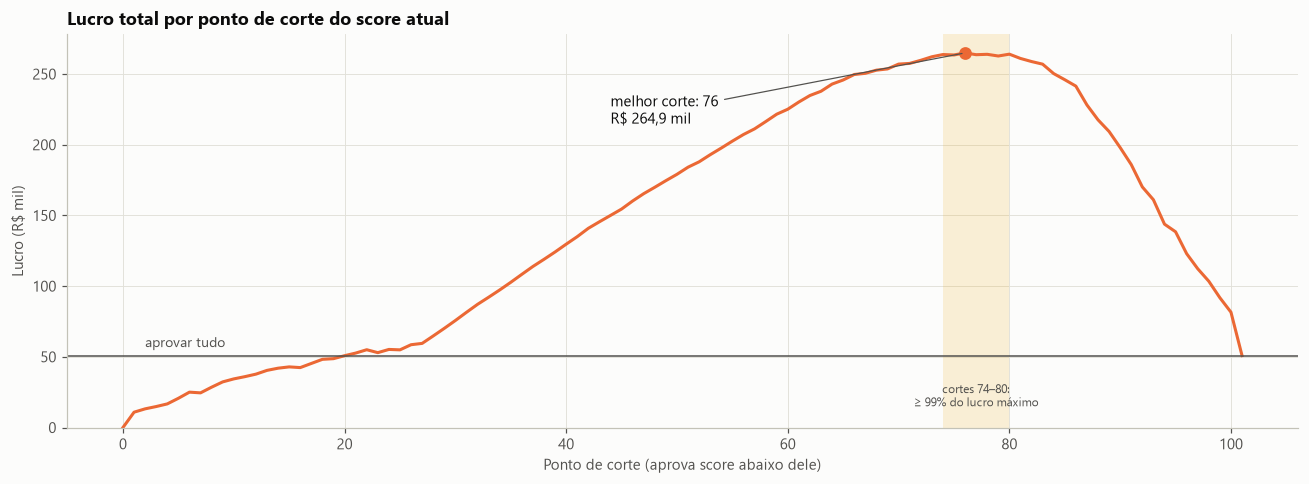

In [4]:
# Faixa de cortes que entrega pelo menos 99% do lucro máximo
plato = curva.loc[curva["lucro"] >= 0.99 * lucro_otimo, "corte"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axvspan(plato.min(), plato.max(), color=gr.AMARELO, alpha=0.15, lw=0)
ax.plot(curva["corte"], curva["lucro"] / 1e3, color=gr.LARANJA)
ax.axhline(lucro_aprovar_tudo / 1e3, color=gr.TINTA_2, lw=1)
ax.text(2, lucro_aprovar_tudo / 1e3 + 6, "aprovar tudo", fontsize=9, color=gr.TINTA_2)
ax.scatter([corte_otimo], [lucro_otimo / 1e3], color=gr.LARANJA, s=70, zorder=3)
ax.annotate(f"melhor corte: {corte_otimo}\n{rs(lucro_otimo)}", xy=(corte_otimo, lucro_otimo / 1e3),
            xytext=(corte_otimo - 32, lucro_otimo / 1e3 - 50), fontsize=10,
            arrowprops=dict(arrowstyle="-", color=gr.TINTA_2, lw=0.8))
ax.text((plato.min() + plato.max()) / 2, 15, f"cortes {plato.min()}–{plato.max()}:\n≥ 99% do lucro máximo",
        ha="center", fontsize=8, color=gr.TINTA_2)
ax.set(title="Lucro total por ponto de corte do score atual", xlabel="Ponto de corte (aprova score abaixo dele)",
       ylabel="Lucro (R$ mil)", ylim=(0, None))
plt.tight_layout()

In [5]:
r = politica(f"corte {corte_otimo}", base["fraude"], base["score"], base["monto"], corte_otimo)
print(f"Com o corte {corte_otimo}:")
print(f"  • lucro de {rs(r['Lucro'])}, {r['Lucro'] / lucro_aprovar_tudo:.1f}x o de aprovar tudo".replace(".", ","))
print(f"  • {pct(r['Pagamentos aprovados'])} dos pagamentos aprovados")
print(f"  • {pct(r['Valor fraudado bloqueado'])} do dinheiro fraudado bloqueado")
print(f"  • {pct(r['Clientes bons bloqueados'])} dos clientes bons bloqueados (o preço da proteção)")

Com o corte 76:
  • lucro de R$ 264,9 mil, 5,2x o de aprovar tudo
  • 77,6% dos pagamentos aprovados
  • 69,2% do dinheiro fraudado bloqueado
  • 20,3% dos clientes bons bloqueados (o preço da proteção)


> **Resposta (pergunta 6):** **aprovar score ≤ 75 e rejeitar score ≥ 76.**

### Por que justamente 76? A regra dos 9%

Para cada valor de score, olhamos **quanto do dinheiro é fraude**. Onde essa fração passa de **9%**,
rejeitar dá mais lucro que aprovar.

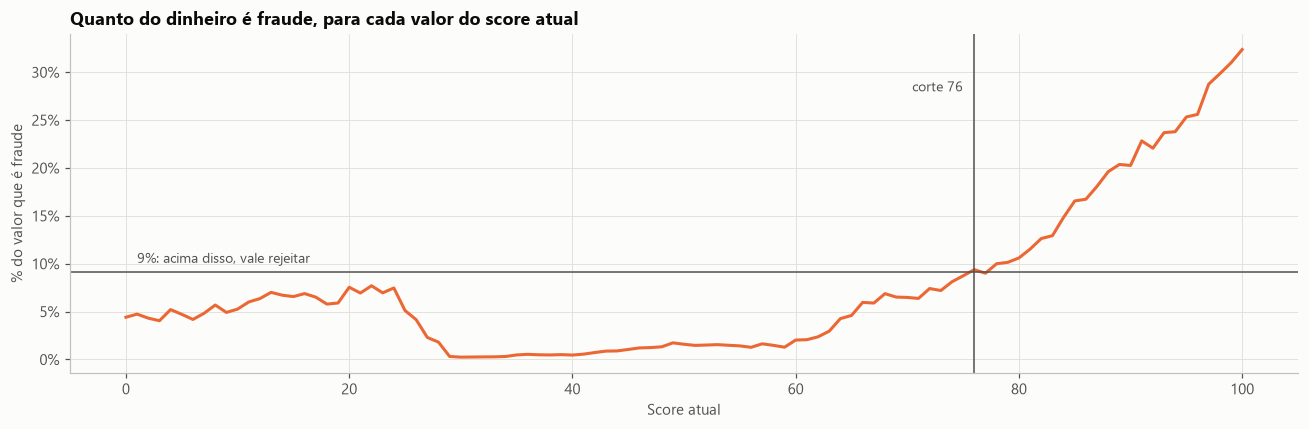

In [6]:
fracao_valor = (base.groupby("score")
                    .apply(lambda g: (g["monto"] * g["fraude"]).sum() / g["monto"].sum())
                    .rolling(5, center=True, min_periods=1).mean())   # média móvel para suavizar o ruído

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(fracao_valor.index, fracao_valor.values, color=gr.LARANJA)
ax.axhline(LIMIAR_9, color=gr.TINTA_2, lw=1)
ax.text(1, LIMIAR_9 + 0.01, "9%: acima disso, vale rejeitar", fontsize=9, color=gr.TINTA_2)
ax.axvline(corte_otimo, color=gr.TINTA_2, lw=1)
ax.text(corte_otimo - 1, 0.28, f"corte {corte_otimo}", ha="right", fontsize=9, color=gr.TINTA_2)
ax.set(title="Quanto do dinheiro é fraude, para cada valor do score atual",
       xlabel="Score atual", ylabel="% do valor que é fraude")
gr.formatar_pct(ax)
plt.tight_layout()

A curva cruza os 9% exatamente perto de **76**. Abaixo disso, a fraude "cabe" na margem dos pagamentos
bons e vale aprovar. Acima, a fraude come mais do que a margem e vale rejeitar.

### O corte é confiável?

Se o melhor corte mudasse muito de um período para outro, não poderíamos confiar nele. 

Portanto, refazemos a busca separadamente em cada conjunto:

In [8]:
linhas = []
for periodo, g in base.groupby("particao", sort=False):
    c = metricas.curva_lucro(g["fraude"], g["score"], g["monto"], cortes=np.arange(0, 102)).set_index("corte")
    nomes = {"treino": "Treino (08/03–31/03)", "validacao": "Validação (01/04–10/04)", "teste": "Teste (11/04–21/04)"}
    print(f"  • {nomes[periodo]}: melhor corte = {int(c['lucro'].idxmax())}; "
          f"o corte {corte_otimo} entrega {pct(c.loc[corte_otimo, 'lucro'] / c['lucro'].max())} do lucro máximo")

  • Treino (08/03–31/03): melhor corte = 76; o corte 76 entrega 100,0% do lucro máximo
  • Validação (01/04–10/04): melhor corte = 73; o corte 76 entrega 96,5% do lucro máximo
  • Teste (11/04–21/04): melhor corte = 77; o corte 76 entrega 99,3% do lucro máximo


O melhor corte fica entre **73 e 77** nos três períodos, e usar 76 em todos entrega de 96,5% a 100%
do máximo possível. **O corte é estável.** Mesmo assim, deve ser revisado periodicamente em produção.

---
# Parte 2 · Quanto o novo modelo vale em R$?

**Comparação justa:** cada modelo escolhe o próprio corte com dados **do passado** (22/03–10/04), e
medimos o lucro **no futuro** (11/04–21/04), exatamente como aconteceria em produção.

O novo modelo dá uma **probabilidade de fraude calibrada** (nb 06). Para ele, a regra dos 9% se aplica
diretamente: rejeitar quando a chance de fraude passa de ~9%.

In [9]:
def melhor_corte(y, risco, valor, cortes):
    c = metricas.curva_lucro(y, risco, valor, cortes=cortes)
    return float(c.loc[c["lucro"].idxmax(), "corte"])

corte_atual_passado = melhor_corte(oof["fraude"], oof["score"], oof["monto"], np.arange(0, 102))
grade = np.unique(np.concatenate([np.quantile(oof["p_modelo"], np.linspace(0, 1, 2001)), [LIMIAR_9]]))
limiar_novo_passado = melhor_corte(oof["fraude"], oof["p_modelo"], oof["monto"], grade)

print(f"Score atual: corte {corte_atual_passado:.0f}")
print(f"Novo modelo: rejeitar se probabilidade ≥ {pct(limiar_novo_passado)}  (a regra dos 9% previa {pct(LIMIAR_9)})")

Score atual: corte 74
Novo modelo: rejeitar se probabilidade ≥ 8,8%  (a regra dos 9% previa 9,1%)


In [10]:
yt, vt = teste["fraude"], teste["monto"]
resultado_teste = pd.DataFrame([
    politica("Aprovar tudo", yt, np.zeros(len(teste)), vt, 1),
    politica(f"Score atual (corte {corte_atual_passado:.0f})", yt, teste["score"], vt, corte_atual_passado),
    politica(f"Novo modelo (prob. ≥ {pct(limiar_novo_passado)})", yt, teste["p_modelo"], vt, limiar_novo_passado),
]).set_index("Política")
ganho = resultado_teste["Lucro"].iloc[2] - resultado_teste["Lucro"].iloc[1]
print(f"Ganho do novo modelo sobre o score atual no teste: {rs(ganho)} "
      f"(+{pct(resultado_teste['Lucro'].iloc[2] / resultado_teste['Lucro'].iloc[1] - 1, 0)})")
tabela(resultado_teste.reset_index().to_dict("records"))

Ganho do novo modelo sobre o score atual no teste: R$ 16,7 mil (+21%)


,Lucro,Pagamentos aprovados,Clientes bons bloqueados,Valor fraudado bloqueado
Política,,,,
Aprovar tudo,"R$ 22,7 mil",100.0%,0.0%,0.0%
Score atual (corte 74),"R$ 79,1 mil",81.2%,16.8%,65.7%
"Novo modelo (prob. ≥ 8,8%)","R$ 95,8 mil",83.9%,13.7%,78.5%


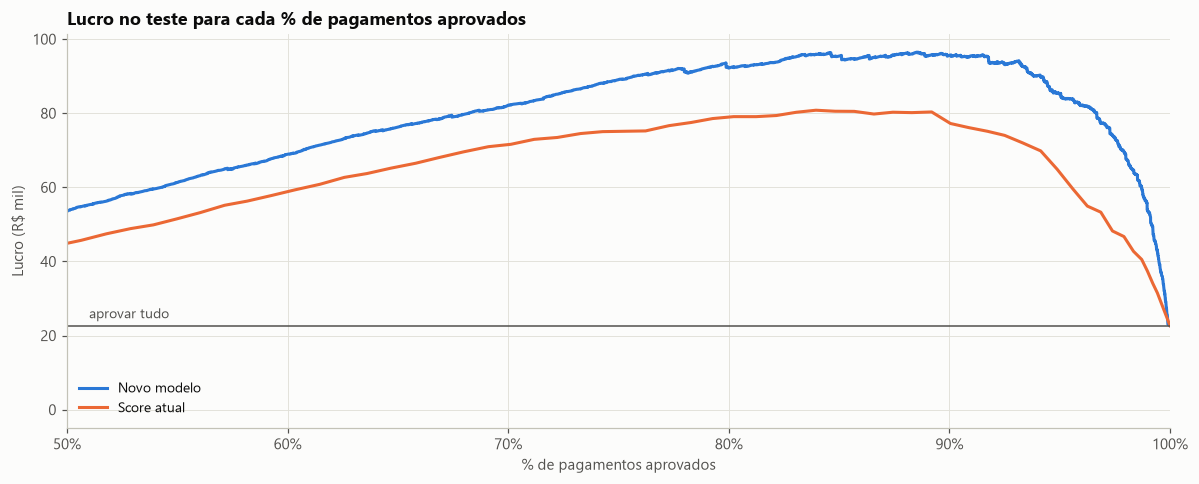

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for nome, risco, cor in [("Novo modelo", teste["p_modelo"], gr.AZUL), ("Score atual", teste["score"], gr.LARANJA)]:
    c = metricas.curva_lucro(yt, risco, vt)
    ax.plot(c["taxa_aprovacao"], c["lucro"] / 1e3, color=cor, label=nome)
ax.axhline(resultado_teste["Lucro"].iloc[0] / 1e3, color=gr.TINTA_2, lw=1)
ax.text(0.51, resultado_teste["Lucro"].iloc[0] / 1e3 + 2, "aprovar tudo", fontsize=9, color=gr.TINTA_2)
ax.set(title="Lucro no teste para cada % de pagamentos aprovados", xlabel="% de pagamentos aprovados",
       ylabel="Lucro (R$ mil)", xlim=(0.5, 1.0))
gr.formatar_pct(ax, "x")
ax.legend(loc="lower left")
plt.tight_layout()

> **Mensagem-chave:** com a mesma regra de decisão, o novo modelo gera **~21% mais lucro** que o score
> atual no período de teste. E ganha dos dois lados: **aprova mais** clientes, **bloqueia menos clientes
> bons** e **barra mais dinheiro fraudado**. No gráfico, a curva azul fica acima da laranja para
> qualquer % de aprovação.

O limiar escolhido no passado (~8,8%) é praticamente a regra dos 9%. Gravamos esse limiar no artefato
de produção, para que a API use exatamente esta política:

In [12]:
artefato = ModeloFraude.carregar(cfg.ARQUIVO_MODELO)
artefato.limiar = limiar_novo_passado
artefato.metadados["politica"] = {"regra": "rejeitar se probabilidade >= limiar", "limiar": limiar_novo_passado,
                                  "criterio": "lucro máximo em 22/03–10/04 (margem 10%, perda 100%)"}
artefato.salvar(cfg.ARQUIVO_MODELO)
print(f"Limiar salvo no artefato: {artefato.limiar:.4f}")

Limiar salvo no artefato: 0.0877


---
# Parte 3 · E se a fraude custar 10x mais que um bloqueio indevido? *(pergunta 5)*

Agora, o custo é por **pagamento**: deixar passar uma fraude custa **10**; bloquear um cliente bom
custa **1**.

**Raciocínio:** 
- Se a chance de fraude de um pagamento é *p*, aprovar custa em média ***10p*** e rejeitar custa ***1 × (1 − p)***. 
- Vale rejeitar quando ***10p > 1 − p***, ou seja, quando **p > 1/11 ≈ 9%**.

>É a mesma regra dos 9%, porque a proporção é a mesma: 10 para 1.

O limiar padrão dos modelos é **50%** ("bloqueia se é mais provável ser fraude do que não ser"). Logo, com fraude 10x mais cara, 50% pode ser exigente demais. 

Comparamos os dois no período de teste:

In [13]:
def custo(limiar):
    bloqueia = teste["p_modelo"] >= limiar
    return {"Fraudes aprovadas": int((~bloqueia & (yt == 1)).sum()),
            "Clientes bons bloqueados": int((bloqueia & (yt == 0)).sum()),
            "Custo total (FN×10 + FP×1)": metricas.custo_esperado(yt, bloqueia)}

c50, c9 = custo(0.5), custo(LIMIAR_9)
for rotulo, c in [("Limiar 50% (padrão)", c50), ("Limiar 9% (regra 1/11)", c9)]:
    print(f"  • {rotulo}: {milhar(c['Fraudes aprovadas'])} fraudes aprovadas, {milhar(c['Clientes bons bloqueados'])} "
          f"clientes bons bloqueados -> custo total {milhar(c['Custo total (FN×10 + FP×1)'])}")
reducao = 1 - c9["Custo total (FN×10 + FP×1)"] / c50["Custo total (FN×10 + FP×1)"]
print()
print(f"Mudar de 50% para 9% reduz o custo total em {pct(reducao, 0)}.")

  • Limiar 50% (padrão): 1.480 fraudes aprovadas, 236 clientes bons bloqueados -> custo total 15.036
  • Limiar 9% (regra 1/11): 647 fraudes aprovadas, 5.210 clientes bons bloqueados -> custo total 11.680

Mudar de 50% para 9% reduz o custo total em 22%.


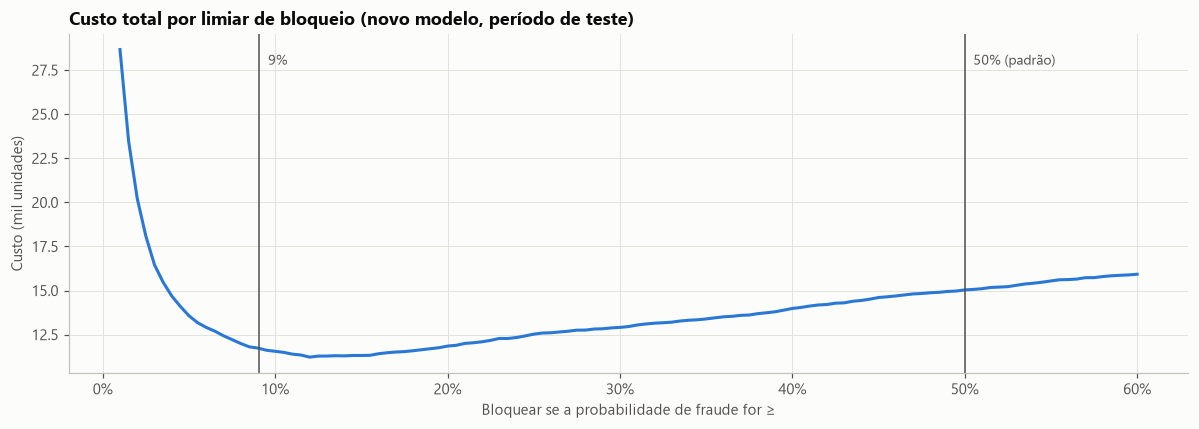

In [14]:
limiares = np.round(np.linspace(0.01, 0.6, 119), 4)
custos = pd.Series([metricas.custo_esperado(yt, teste["p_modelo"] >= l) for l in limiares], index=limiares)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(custos.index, custos.values / 1e3, color=gr.AZUL)
for v, rot in [(0.5, "50% (padrão)"), (LIMIAR_9, "9%")]:
    ax.axvline(v, color=gr.TINTA_2, lw=1)
    ax.text(v + 0.005, custos.max() / 1e3 * 0.97, rot, fontsize=9, color=gr.TINTA_2)
ax.set(title="Custo total por limiar de bloqueio (novo modelo, período de teste)",
       xlabel="Bloquear se a probabilidade de fraude for ≥", ylabel="Custo (mil unidades)")
gr.formatar_pct(ax, "x")
plt.tight_layout()

> **Mensagem-chave:** baixar o limiar de 50% para **9%** corta o custo total em **~22%**. Deixamos
> passar menos da metade das fraudes (647 em vez de 1.480) e, em troca, bloqueamos mais clientes bons.
> Com a fraude custando 10x, essa troca compensa.
>
> No gráfico, o custo é praticamente plano entre ~9% e ~16%. O mínimo exato no teste fica um pouco
> acima de 9% (o modelo superestimou levemente o risco nesse período, nb 07), mas a diferença é pequena.
> O que importa é sair de 50% e ir para a região de ~10%.

**O que mais muda com essa informação (resumo da resposta 5):**
1. **Limiar de 50% → 9%**, sem precisar retreinar o modelo, porque ele é calibrado. Se a razão de
   custos mudar (de 10x para 8x, por exemplo), basta mudar o limiar.
2. **Medir o modelo pelo custo**, e não por acurácia: com 5% de fraude, "aprovar tudo" já tem 95% de
   acurácia.
3. **Criar uma zona cinzenta:** pagamentos de risco intermediário vão para autenticação extra (3DS,
   biometria) ou revisão manual, em vez de bloqueio direto. Isso reduz o atrito dos bloqueios a mais.
4. **Validar o "1x" do cliente bloqueado** com o negócio: perder um bom cliente pode custar mais que uma
   venda.

---
# Apêndice técnico

### A.1 De onde vem o 1/11

Para um pagamento de valor $m$ e probabilidade de fraude $p$:

$$\text{E[resultado | aprovar]} = 0{,}10 \cdot m \cdot (1-p) - 1{,}00 \cdot m \cdot p \qquad \text{E[resultado | rejeitar]} = 0$$

Aprovar compensa quando $0{,}10(1-p) > p \iff p < 0{,}10 / 1{,}10 = 1/11$. O valor $m$ some da
desigualdade: para um modelo **calibrado**, o limiar não depende do valor do pagamento. Na pergunta 5,
com custos $C_{FN}=10$ e $C_{FP}=1$, o limiar é $C_{FP}/(C_{FP}+C_{FN}) = 1/11$.

O score atual **não é calibrado**: é um percentil de 0 a 100, cada valor com ~1% das transações (nb 02).
Por isso o corte dele foi buscado diretamente pelo lucro, e não pela fórmula.

### A.2 Incerteza do corte do score atual (bootstrap)
Reamostramos as transações 500 vezes e refazemos a busca do melhor corte.

In [15]:
rng = np.random.default_rng(cfg.SEED)
res = metricas.resultado_transacao(base["fraude"], base["monto"])
sc = base["score"].to_numpy()
melhores = []
for _ in range(500):
    idx = rng.integers(0, len(base), len(base))
    lucro_por_score = np.bincount(sc[idx], weights=res[idx], minlength=101)
    melhores.append(int(np.argmax(np.concatenate([[0], np.cumsum(lucro_por_score)]))))
melhores = pd.Series(melhores)
print(f"Intervalo de 90% do melhor corte: [{melhores.quantile(0.05):.0f}, {melhores.quantile(0.95):.0f}] | "
      f"mais frequente: {melhores.mode()[0]}")

Intervalo de 90% do melhor corte: [73, 81] | mais frequente: 76


### A.3 Treinar "sabendo" do custo vs. mover o limiar

Outra forma de lidar com o custo 10:1 é dar **peso 10 às fraudes** no treino e manter o limiar em 50%.
Pela teoria, as duas abordagens são equivalentes. Testamos:

In [16]:
%%time
dev = base[base["particao"] != "teste"].reset_index(drop=True)
te = base[base["particao"] == "teste"].reset_index(drop=True)
cf = ConstrutorFeatures()
X_dev = cf.fit_transform(dev, dev["fraude"])
X_te = cf.transform(te)[X_dev.columns]
pesado = lgb.LGBMClassifier(**artefato.metadados["hiperparametros"]).fit(
    X_dev, dev["fraude"], sample_weight=np.where(dev["fraude"] == 1, 10.0, 1.0))
p_pesado = pesado.predict_proba(X_te)[:, 1]

for nome, p, lim in [("Sem peso + calibração + limiar 9%", teste["p_modelo"], LIMIAR_9),
                     ("Peso 10 nas fraudes + limiar 50%", p_pesado, 0.5)]:
    print(f"  • {nome}: custo {milhar(metricas.custo_esperado(yt, p >= lim))} | PR AUC {average_precision_score(yt, p):.3f}".replace("0.", "0,"))

  • Sem peso + calibração + limiar 9%: custo 11.680 | PR AUC 0,368
  • Peso 10 nas fraudes + limiar 50%: custo 11.502 | PR AUC 0,365
CPU times: total: 23.7 s
Wall time: 24.1 s


Os custos ficam muito próximos (~1,5% de diferença, com a versão com peso levemente à frente neste
período), como prevê a teoria, e a versão com peso perde um pouco de PR AUC. Preferimos **não usar peso**: uma única probabilidade calibrada atende a qualquer razão
de custos, mudando só o limiar.